### Common libraries and `mpl` settings

In [1]:
from pathlib import Path
import gzip

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from cmcrameri import cm as cmc
from itertools import islice
from collections import deque
from concurrent.futures import ThreadPoolExecutor

MM = 1.0 / 25.4

mpl.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.fallback": "stix",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "legend.frameon": False,
        "axes.grid": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

out_folder = Path.cwd() / "figures"
out_folder.mkdir(exist_ok=True)

bubble_colors = cmc.batlow(np.linspace(0.18, 0.72, 3))

## Data preparation from MD
Run the following extraction cells only when the complete MD calculation results are available in `single_fiber/heat/results/`. The plotting cells below use only `pp_data/`.

### Figure 8 — W-fragmentation distributions

In [ ]:
root = Path("../single_fiber/heat/results/TMB/phi006")
output = Path("pp_data/w_fragmentation.npz")
output.parent.mkdir(exist_ok=True)
states = ["he0", "he1", "he2"]
seeds = range(42, 52)
alpha = 400
t_grid = np.arange(-10.0, 51.0)
n_grid = np.geomspace(1, 1e5, 201)
cases = np.array([(s, alpha) for s in states], dtype=object)
F = np.empty((len(states), len(seeds), len(t_grid), len(n_grid)), dtype=np.float32)
M = np.empty((len(states), len(seeds), len(t_grid)), dtype=np.float32)

for i, state in enumerate(states):
    for j, seed in enumerate(seeds):
        run = root / f"s{seed}" / state / f"alpha_{alpha:.1f}"
        tc = float(pd.read_csv(run / "heat_off.txt", sep=r"\s+").iloc[0].time_ps)
        parts = []
        for chunk in pd.read_csv(
            run / "w_clusters.txt.gz",
            sep=r"\s+",
            usecols=["time_ps", "N_W"],
            chunksize=200000,
        ):
            part = chunk[chunk.time_ps.between(tc - 11, tc + 51)]
            if len(part):
                parts.append(part)
            if chunk.time_ps.iloc[-1] > tc + 51:
                break
        d = pd.concat(parts)
        times, masses, fractions = [], [], []
        for t, g in d.groupby("time_ps", sort=True):
            n = np.sort(g.N_W.to_numpy(dtype=np.int64))
            mass = n.sum()
            cumulative = np.r_[0, np.cumsum(n)]
            times.append(t)
            masses.append(mass)
            fractions.append(
                (mass - cumulative[np.searchsorted(n, n_grid, side="right")]) / mass
            )
        times = np.asarray(times)
        masses = np.asarray(masses)
        fractions = np.asarray(fractions)
        target = tc + t_grid
        k = np.clip(np.searchsorted(times, target, side="right"), 1, len(times) - 1)
        w = (target - times[k - 1]) / (times[k] - times[k - 1])
        M[i, j] = (1 - w) * masses[k - 1] + w * masses[k]
        F[i, j] = (1 - w[:, None]) * fractions[k - 1] + w[:, None] * fractions[k]

np.savez_compressed(output, F=F, M=M, t_grid=t_grid, n_grid=n_grid, cases=cases)

### Figure 9 — outward W energy

In [ ]:
root = Path("../single_fiber/heat")
pp = Path("pp_data")
pp.mkdir(exist_ok=True)

bins = np.arange(-1000.0, 305.0, 5.0)
alphas = (100, 200, 400, 800)
seeds = range(42, 52)

cases = (
    [("phi000", f"s{s}", "he0", a) for s in range(10) for a in alphas]
    + [
        (p, f"s{s}", h, a)
        for p in ("phi003", "phi009", "phi012")
        for s in seeds
        for h in ("he0", "he2")
        for a in alphas
    ]
    + [
        ("phi006", f"s{s}", h, a)
        for s in seeds
        for h in ("he0", "he1", "he2")
        for a in alphas
    ]
)

assert len(cases) == len(set(cases)) == 400


def process_case(case, seed, state, alpha):
    sub = Path(case, seed, state, f"alpha_{alpha:.1f}")
    run = root / "results/TMB" / sub
    pe = run / "w_cluster_energy.txt.gz"

    d = pd.read_csv(run / "w_clusters.txt.gz", sep=r"\s+")
    times, idx = np.unique(d.time_ps.to_numpy(), return_inverse=True)
    dt = np.gradient(times)
    dt[[0, -1]] *= 0.5

    initial = d[d.time_ps == times[0]]
    n0 = int(initial.N_W.sum())
    k0 = initial.K_total_eV.sum() / n0

    x, y = d.x_com_A.to_numpy(), d.y_com_A.to_numpy()
    r = np.hypot(x, y)
    s = r / 10 - 5.031
    vr = (
        np.divide(
            x * d.vx_com_Aps.to_numpy() + y * d.vy_com_Aps.to_numpy(),
            r,
            out=np.zeros_like(r),
            where=r > 0,
        )
        / 10
    )

    mask = (d.wrap_z.to_numpy() == 0) & (vr > 0) & (s >= 1) & (s < 25)
    a = d.loc[mask].copy().reset_index(drop=True)
    a["s"] = s[mask]
    a["w"] = vr[mask] * dt[idx[mask]] / 2
    a["step"] = np.rint(a.time_ps.to_numpy() * 1000).astype(np.int64)

    indices = {
        step: dict(zip(g.cluster_id.to_numpy(), g.index.to_numpy()))
        for step, g in a.groupby("step", sort=False)
    }

    n = a.N_W.to_numpy()
    uexc = np.full(len(a), np.nan)

    with gzip.open(pe, "rb") as f:
        for _ in range(3):
            next(f)

        for header in f:
            step, nchunks, _ = map(int, header.split())
            matched = indices.get(step)

            if matched is None:
                deque(islice(f, nchunks), maxlen=0)
                continue

            for line in islice(f, nchunks):
                fields = line.split()
                i = matched.get(int(fields[1]))
                if i is not None and int(fields[2]) == n[i]:
                    uexc[i] = float(fields[6])

    valid = np.isfinite(uexc)
    coverage = (a.w.to_numpy()[valid] * n[valid]).sum() / (a.w.to_numpy() * n).sum()

    if coverage < 0.99:
        raise ValueError(f"{sub}: energy matching {coverage:.2%}")

    a = a.loc[valid].copy().reset_index(drop=True)
    a["WN"] = a.w * a.N_W
    a["E_MD"] = a.w * (a.K_total_eV - a.N_W * k0 + uexc[valid])

    tr = sub.as_posix()
    p = int(case[3:])
    shell_new = []

    for distance in range(2, 25):
        b = a[(a.s >= distance - 1) & (a.s < distance + 1)]
        shell_new.append((tr, p, state, alpha, distance, b.WN.sum(), b.E_MD.sum() / n0))

    rate_new = []

    if case == "phi006" and seed == "s44" and state == "he2":
        tc = pd.read_csv(run / "heat_off.txt", sep=r"\s+").time_ps.iloc[0]
        b = a[(a.s >= 23) & (a.s < 25)]
        rate = np.histogram(
            b.time_ps.to_numpy() - tc, bins=bins, weights=b.E_MD.to_numpy()
        )[0] / (5 * n0)

        rate_new = [(alpha, t, e) for t, e in zip((bins[:-1] + bins[1:]) / 2, rate)]

    return shell_new, rate_new


shell_rows = []
rate_rows = []

with ThreadPoolExecutor(max_workers=4) as pool:
    for start in range(0, len(cases), 4):
        batch = cases[start : start + 4]
        results = list(pool.map(lambda c: process_case(*c), batch))

        for sr, rr in results:
            shell_rows.extend(sr)
            rate_rows.extend(rr)

        shell = pd.DataFrame(
            shell_rows,
            columns=[
                "trajectory",
                "p",
                "state",
                "alpha",
                "distance_nm",
                "WN",
                "E_norm",
            ],
        )

        source = pd.DataFrame(rate_rows, columns=["alpha", "time_rel_ps", "E_rate"])

        print(f"Processed: {min(start + 4, len(cases))}/400", flush=True)

assert shell.trajectory.nunique() == 400
assert source.alpha.nunique() == 4

shell.to_csv(pp / "w_energy_shell.csv", index=False)
source.to_csv(pp / "w_energy_rates.csv", index=False)

print("Trajectories:", shell.trajectory.nunique())
print("Spatial profiles:", len(shell))
print("Temporal profiles:", source.alpha.nunique())

### Figure 9 — empirical energy fit
Fit all 400 individual trajectories and evaluate the fit MARD and leave-one-geometry-out diagnostics.

In [ ]:
base = pd.read_csv("pp_data/w_energy_shell.csv")
base = base.loc[base.distance_nm.eq(24)].copy().reset_index(drop=True)

base["HeV"] = base.state.str[-1].astype(int)
base["seed"] = base.trajectory.str.extract(r"/(s\d+)/")[0]
base["geom"] = base.p.astype(str) + "/" + base.seed

p = base.p.to_numpy() / 100
h = base.HeV.to_numpy()
a = base.alpha.to_numpy()
chi = p * h / (1 - p)

X = np.column_stack([np.ones(len(base)), a / 400, p, chi])

y = base.E_norm.to_numpy()
coef = np.linalg.lstsq(X, y, rcond=None)[0]
base["E_fit"] = X @ coef

held = np.empty(len(base))
for geom in base.geom.unique():
    test = base.geom.eq(geom).to_numpy()
    b = np.linalg.lstsq(X[~test], y[~test], rcond=None)[0]
    held[test] = X[test] @ b

err_fit = 100 * np.abs(base.E_fit.to_numpy() / y - 1)
err_logo = 100 * np.abs(held / y - 1)

print("Coefficients:", coef)
print(f"Fit MARD: {err_fit.mean():.3f}%")
print(f"LOGO MARD: {err_logo.mean():.3f}%")
print(f"LOGO median: {np.median(err_logo):.3f}%")
print(f"LOGO P90: {np.percentile(err_logo, 90):.3f}%")
print(f"LOGO max: {err_logo.max():.3f}%")

base.to_csv("pp_data/w_energy_AHP.csv", index=False)

## Figures from processed data
The three snapshot images for Figure 7 are stored in `figures/fragmentation_preview/`.

### Figure 8

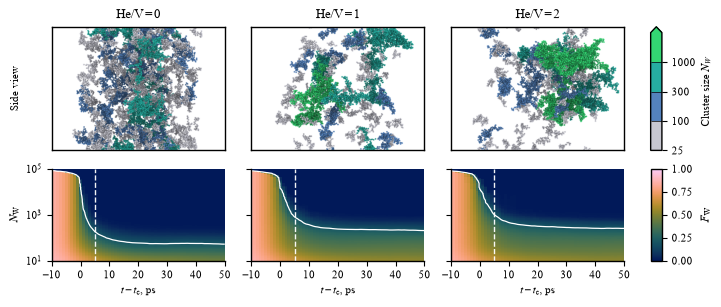

In [2]:
d = np.load("./pp_data/w_fragmentation.npz", allow_pickle=True)

F = d["F"]
M = d["M"]
t_grid = d["t_grid"]
n_grid = d["n_grid"]
cases = d["cases"]

state_order = ["he0", "he1", "he2"]
alpha = 400

case_to_idx = {(cases[i, 0], int(cases[i, 1])): i for i in range(len(cases))}


def pooled_fraction(i):
    w = M[i][:, :, None]
    return np.sum(F[i] * w, axis=0) / np.sum(w, axis=0)


t_edges = np.empty(len(t_grid) + 1)
t_edges[1:-1] = 0.5 * (t_grid[:-1] + t_grid[1:])
t_edges[0] = t_grid[0] - 0.5 * (t_grid[1] - t_grid[0])
t_edges[-1] = t_grid[-1] + 0.5 * (t_grid[-1] - t_grid[-2])

logn = np.log10(n_grid)
logn_edges = np.empty(len(logn) + 1)
logn_edges[1:-1] = 0.5 * (logn[:-1] + logn[1:])
logn_edges[0] = logn[0] - 0.5 * (logn[1] - logn[0])
logn_edges[-1] = logn[-1] + 0.5 * (logn[-1] - logn[-2])
n_edges = 10**logn_edges

seed = 44
dt = 5.0
min_cluster_size = 25

snap_dir = Path.cwd() / "figures" / "fragmentation_preview"
snap_paths = {
    state: snap_dir / f"s{seed}_{state}_tcplus{dt:g}_N{min_cluster_size}.png"
    for state in state_order
}

snap_colors = [
    [0.78, 0.78, 0.82],  # 25-99
    [0.33, 0.51, 0.74],  # 100-299
    [0.15, 0.68, 0.63],  # 300-999
    [0.20, 0.84, 0.45],  # >=1000
]
snap_cmap = mcolors.ListedColormap(snap_colors)
snap_norm = mcolors.BoundaryNorm([0, 1, 2, 3, 4], snap_cmap.N)

fig = plt.figure(figsize=(200 * MM, 82 * MM))

gs = GridSpec(
    2,
    4,
    figure=fig,
    width_ratios=[1, 1, 1, 0.065],
    height_ratios=[1.0, 0.6],
    hspace=0.03,
)

ax_snap = [fig.add_subplot(gs[0, j]) for j in range(3)]
ax_map = [fig.add_subplot(gs[1, j]) for j in range(3)]
cax_snap = fig.add_subplot(gs[0, 3])
cax_map = fig.add_subplot(gs[1, 3])
titles = [r"$\mathrm{He/V}=0$", r"$\mathrm{He/V}=1$", r"$\mathrm{He/V}=2$"]

for j, state in enumerate(state_order):
    img = plt.imread(snap_paths[state])
    ax = ax_snap[j]

    ax.imshow(img)
    ax.set_title(titles[j], fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_box_aspect(img.shape[0] / img.shape[1])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_edgecolor("black")

ax_snap[0].set_ylabel("Side view")

cmap_heat = cmc.batlow
levels = [0.2]

for j, state in enumerate(state_order):
    ax = ax_map[j]
    k = case_to_idx[(state, alpha)]
    Z = pooled_fraction(k)

    im = ax.pcolormesh(
        t_edges,
        n_edges,
        Z.T,
        cmap=cmap_heat,
        vmin=0.0,
        vmax=1.0,
        shading="flat",
        rasterized=True,
    )

    ax.contour(t_grid, n_grid, Z.T, levels=levels, colors="white", linewidths=0.9)

    ax.axvline(dt, color="white", lw=1.0, ls="--", alpha=0.95)

    ax.set_yscale("log")
    ax.set_xlim(t_grid[0], t_grid[-1])
    ax.set_ylim(10, 1e5)
    ax.set_xlabel(r"$t-t_{\mathrm{c}},\,\mathrm{ps}$")
    ax.set_xticks([-10, 0, 10, 20, 30, 40, 50])

    if j == 0:
        ax.set_ylabel(r"$N_\mathrm{W}$")
    else:
        ax.set_ylabel("")
        ax.tick_params(axis="y", which="both", labelleft=False)

sm_snap = ScalarMappable(norm=snap_norm, cmap=snap_cmap)
sm_snap.set_array([])

cbar_snap = fig.colorbar(
    sm_snap,
    cax=cax_snap,
    boundaries=[0, 1, 2, 3, 4],
    ticks=[0, 1, 2, 3],
    spacing="uniform",
    drawedges=True,
    extend="max",
)
cbar_snap.ax.minorticks_off()
segments = cbar_snap.dividers.get_segments()
cbar_snap.dividers.set_segments(segments[:-1])

cbar_snap.ax.set_yticklabels(["25", "100", "300", "1000"])
cbar_snap.set_label(r"Cluster size $N_W$")

cbar_map = fig.colorbar(im, cax=cax_map, ticks=[0, 0.25, 0.5, 0.75, 1.0])
cbar_map.set_label(r"$F_\mathrm{W}$")

fig.canvas.draw()

p = ax_snap[-1].get_position()
q = cax_snap.get_position()

cax_snap.set_in_layout(False)
cax_snap.set_position(
    [
        q.x0,
        p.y0,
        q.width,
        p.height,
    ]
)

fig.align_ylabels()

fig.savefig(
    out_folder / "W_fragments.png", pad_inches=0.0, bbox_inches="tight", dpi=500
)

plt.show()

### Figure 9

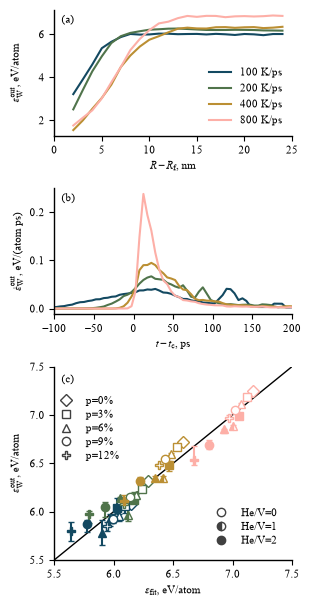

In [4]:
shell = pd.read_csv("pp_data/w_energy_shell.csv")
source = pd.read_csv("pp_data/w_energy_rates.csv")
base = pd.read_csv("pp_data/w_energy_AHP.csv")

alpha_colors = dict(zip((100, 200, 400, 800), cmc.batlow(np.linspace(0.15, 0.85, 4))))
markers = {0: "D", 3: "s", 6: "^", 9: "o", 12: "P"}
fillstyles = {0: "none", 1: "left", 2: "full"}

rep = shell[
    (shell.p == 6) & (shell.state == "he2") & shell.trajectory.str.contains("/s44/")
]

summary = base.groupby(["p", "HeV", "alpha"], as_index=False).agg(
    E_fit=("E_fit", "first"),
    E_med=("E_norm", "median"),
    E_q25=("E_norm", lambda x: x.quantile(0.25)),
    E_q75=("E_norm", lambda x: x.quantile(0.75)),
)

fig, (ax0, ax1, ax2) = plt.subplots(
    3, 1, figsize=(80 * MM, 155 * MM), gridspec_kw={"height_ratios": [0.75, 0.75, 1.15]}
)

for alpha, d in rep.groupby("alpha"):
    d = d.sort_values("distance_nm")
    ax0.plot(
        d.distance_nm,
        d.E_norm,
        color=alpha_colors[int(alpha)],
        lw=1.5,
        label=f"{int(alpha)} K/ps",
    )

ax0.set(
    xlim=(0, 25),
    xlabel=r"$R-R_{\rm f}$, nm",
    ylabel=r"$\varepsilon_{\mathrm{W}}^{\mathrm{out}}$, eV/atom",
)
ax0.text(0.03, 0.96, "(a)", transform=ax0.transAxes, va="top")
ax0.legend(loc="lower right")

for alpha, d in source.groupby("alpha"):
    d = d.sort_values("time_rel_ps")
    ax1.plot(d.time_rel_ps, d.E_rate, color=alpha_colors[int(alpha)], lw=1.5)

ax1.set(
    xlim=(-100, 200),
    xlabel=r"$t-t_{\rm c}$, ps",
    ylabel=r"$\dot{\varepsilon}_{\mathrm{W}}^{\mathrm{out}}$, eV/(atom ps)",
    xticks=[-100, -50, 0, 50, 100, 150, 200],
)
ax1.text(0.03, 0.96, "(b)", transform=ax1.transAxes, va="top")

for row in summary.itertuples():
    c = alpha_colors[int(row.alpha)]
    empty = int(row.HeV) == 0

    ax2.errorbar(
        row.E_fit,
        row.E_med,
        yerr=[[row.E_med - row.E_q25], [row.E_q75 - row.E_med]],
        fmt="none",
        ecolor=c,
        elinewidth=1.5,
        capsize=2,
        zorder=2,
    )

    ax2.plot(
        row.E_fit,
        row.E_med,
        marker=markers[int(row.p)],
        ms=6,
        linestyle="none",
        fillstyle="full" if empty else fillstyles[int(row.HeV)],
        markerfacecolor=ax2.get_facecolor() if empty else c,
        markerfacecoloralt=ax2.get_facecolor(),
        markeredgecolor=c,
        markeredgewidth=1,
        zorder=3,
    )

ax2.plot([5.5, 7.5], [5.5, 7.5], color="0", lw=1, zorder=1)

ax2.set(
    ylabel=r"$\varepsilon_{\mathrm{W}}^{\mathrm{out}}$, eV/atom",
    xlabel=r"$\varepsilon_{\mathrm{fit}}$, eV/atom",
)
ax2.set_xticks([5.5, 6.0, 6.5, 7.0, 7.5])
ax2.set_yticks([5.5, 6.0, 6.5, 7.0, 7.5])
ax2.set_xlim(5.5, 7.5)
ax2.set_ylim(5.5, 7.5)
ax2.text(0.03, 0.96, "(c)", transform=ax2.transAxes, va="top")

p_handles = [
    Line2D(
        [],
        [],
        marker=markers[p],
        linestyle="none",
        color="0.25",
        markerfacecolor="white",
        markersize=6,
        label=f"p={p}%",
    )
    for p in (0, 3, 6, 9, 12)
]

hev_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="none",
        color="0.25",
        markersize=6,
        fillstyle=fillstyles[h],
        markerfacecolor="0.25",
        markerfacecoloralt="white",
        label=f"He/V={h}",
    )
    for h in (0, 1, 2)
]

leg = ax2.legend(
    handles=p_handles, loc="upper left", bbox_to_anchor=(-0.04, 0.9), labelspacing=0.3
)
ax2.add_artist(leg)

ax2.legend(
    handles=hev_handles,
    loc="lower right",
    bbox_to_anchor=(0.98, 0.02),
    labelspacing=0.3,
)

fig.subplots_adjust(hspace=0.35)
fig.align_ylabels()
fig.tight_layout()

fig.savefig(out_folder / "W_energy.pdf", bbox_inches="tight", pad_inches=0)

plt.show()

In [6]:
rep = shell[
    (shell.p == 6)
    & (shell.state == "he2")
    & shell.trajectory.str.contains("/s44/")
    & (shell.distance_nm == 24)
]

E = rep.set_index("alpha").E_norm
rates = source.groupby("alpha").E_rate.max()

print(f"100 K/ps: {E.loc[100]:.4f} eV/W")
print(f"800 K/ps: {E.loc[800]:.4f} eV/W")
print(f"Energy increase: {100 * (E.loc[800] / E.loc[100] - 1):.2f}%")
print(f"Peak rate ratio: {rates.loc[800] / rates.loc[100]:.2f}")

100 K/ps: 6.0073 eV/W
800 K/ps: 6.8490 eV/W
Energy increase: 14.01%
Peak rate ratio: 5.81
